In [2]:
import sys
import os

print("Python interpreter:")
print(sys.executable)

print("\nTrenutni direktorij:")
print(os.getcwd())

Python interpreter:
C:\Users\Nina\anaconda3\envs\diplomski\python.exe

Trenutni direktorij:
C:\Users\Nina\Desktop\Diplomski\Notebooks


In [3]:
import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("Biblioteke uspješno učitane.")
print("TensorFlow verzija:", tf.__version__)

Biblioteke uspješno učitane.
TensorFlow verzija: 2.21.0


In [4]:
DATASET_PATH = "../Dataset"
SPLIT_DATASET_PATH = "../Dataset_Splitted"

IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

print("Izvorni dataset:", DATASET_PATH)
print("Podijeljeni dataset:", SPLIT_DATASET_PATH)
print("Veličina slike:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Seed:", SEED)

Izvorni dataset: ../Dataset
Podijeljeni dataset: ../Dataset_Splitted
Veličina slike: 224
Batch size: 32
Seed: 42


In [5]:
if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Mapa {DATASET_PATH} ne postoji."
    )

class_names_original = sorted([
    folder
    for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

print("Klase u izvornom datasetu:")

for class_name in class_names_original:
    print(class_name)

Klase u izvornom datasetu:
Mild_DR
Moderate_DR
No_DR
Proliferate_DR
Severe_DR


In [6]:
class_counts = {}

for class_name in class_names_original:
    class_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        file_name
        for file_name in os.listdir(class_path)
        if file_name.lower().endswith(
            (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
        )
    ]

    class_counts[class_name] = len(image_files)

print("Broj slika po klasama:\n")

for class_name, count in class_counts.items():
    print(f"{class_name:18s}: {count}")

print("\nUkupan broj slika:", sum(class_counts.values()))

Broj slika po klasama:

Mild_DR           : 370
Moderate_DR       : 999
No_DR             : 1805
Proliferate_DR    : 295
Severe_DR         : 193

Ukupan broj slika: 3662


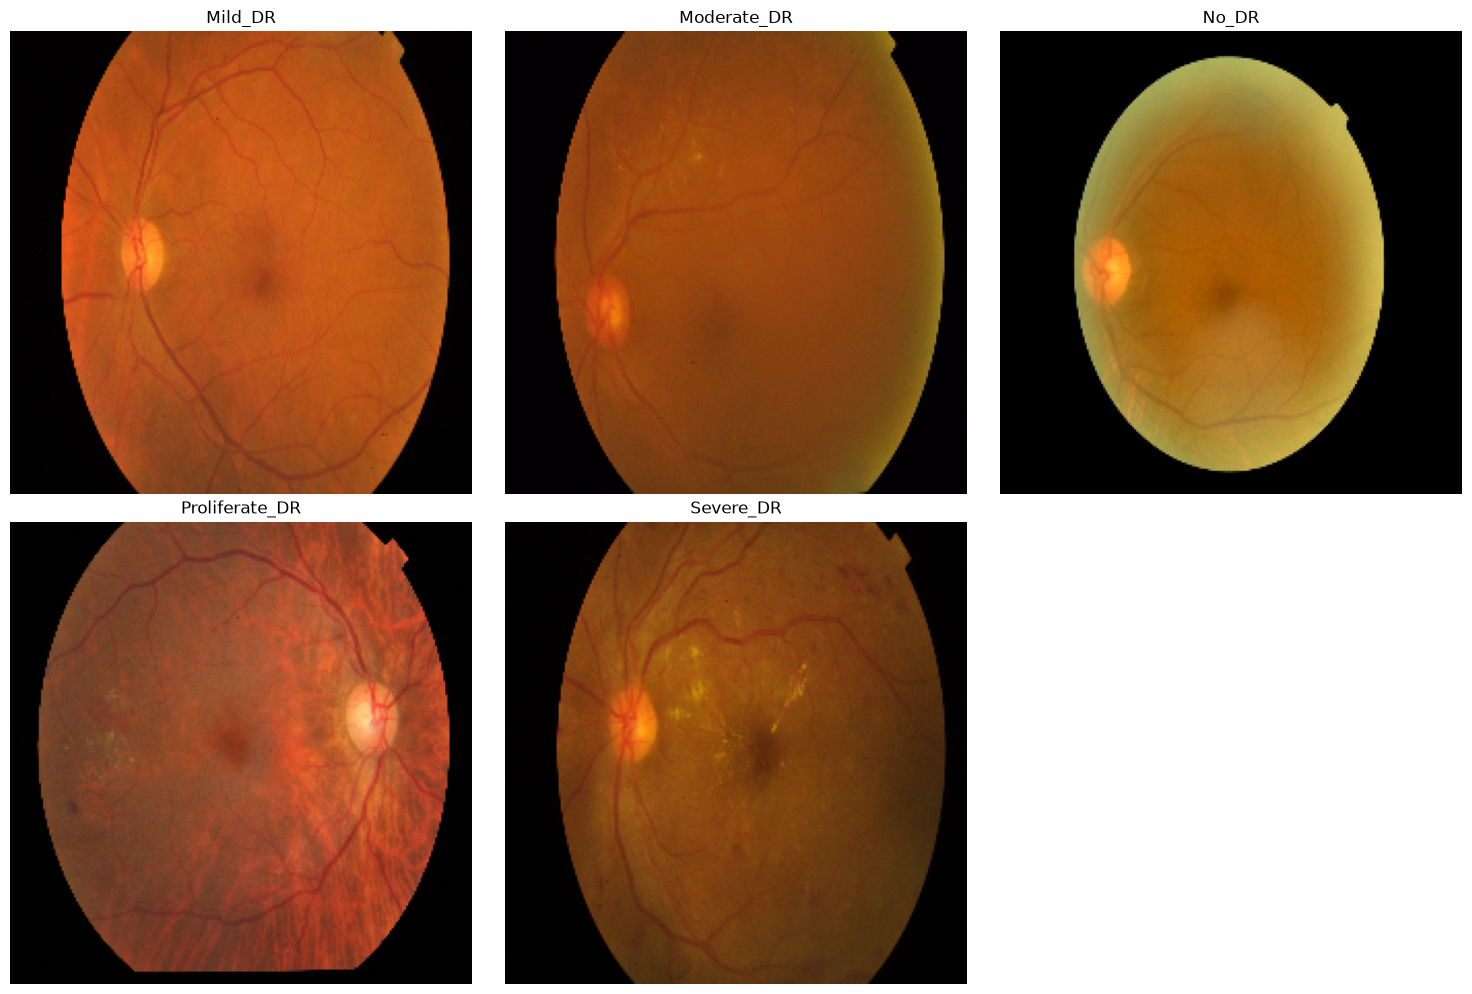

In [7]:
plt.figure(figsize=(15, 10))

for index, class_name in enumerate(class_names_original):
    class_path = os.path.join(DATASET_PATH, class_name)

    image_files = [
        file_name
        for file_name in os.listdir(class_path)
        if file_name.lower().endswith(
            (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
        )
    ]

    image_name = random.choice(image_files)
    image_path = os.path.join(class_path, image_name)

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Slika se ne može učitati: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, index + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
%pip install split-folders

Note: you may need to restart the kernel to use updated packages.


In [9]:
import splitfolders

if not os.path.exists(SPLIT_DATASET_PATH):
    splitfolders.ratio(
        DATASET_PATH,
        output=SPLIT_DATASET_PATH,
        seed=SEED,
        ratio=(0.70, 0.15, 0.15)
    )

    print("Podjela dataseta završena.")
else:
    print("Dataset je već podijeljen.")

Dataset je već podijeljen.


In [10]:
base_path = Path(SPLIT_DATASET_PATH)

for split_name in ["train", "val", "test"]:
    split_path = base_path / split_name

    if not split_path.exists():
        raise FileNotFoundError(
            f"Nedostaje mapa: {split_path}"
        )

    print(f"\n{split_name.upper()}")

    total_images = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = split_path / class_name

        if not class_path.is_dir():
            continue

        image_count = len([
            file_name
            for file_name in os.listdir(class_path)
            if file_name.lower().endswith(
                (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
            )
        ])

        total_images += image_count

        print(f"{class_name:18s}: {image_count}")

    print(f"Ukupno: {total_images}")


TRAIN
Mild_DR           : 259
Moderate_DR       : 699
No_DR             : 1263
Proliferate_DR    : 206
Severe_DR         : 135
Ukupno: 2562

VAL
Mild_DR           : 55
Moderate_DR       : 149
No_DR             : 270
Proliferate_DR    : 44
Severe_DR         : 28
Ukupno: 546

TEST
Mild_DR           : 56
Moderate_DR       : 151
No_DR             : 272
Proliferate_DR    : 45
Severe_DR         : 30
Ukupno: 554


In [11]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)

evaluation_datagen = ImageDataGenerator()

In [12]:
train_generator = train_datagen.flow_from_directory(
    os.path.join(SPLIT_DATASET_PATH, "train"),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

Found 2562 images belonging to 5 classes.


In [13]:
validation_generator = evaluation_datagen.flow_from_directory(
    os.path.join(SPLIT_DATASET_PATH, "val"),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 546 images belonging to 5 classes.


In [14]:
test_generator = evaluation_datagen.flow_from_directory(
    os.path.join(SPLIT_DATASET_PATH, "test"),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 554 images belonging to 5 classes.


In [15]:
print("Train rescale:", train_datagen.rescale)
print("Evaluation rescale:", evaluation_datagen.rescale)

Train rescale: None
Evaluation rescale: None


In [16]:
images, labels = next(train_generator)

print("Dimenzije batcha:", images.shape)
print("Dimenzije oznaka:", labels.shape)
print("Minimalna vrijednost piksela:", images.min())
print("Maksimalna vrijednost piksela:", images.max())

Dimenzije batcha: (32, 224, 224, 3)
Dimenzije oznaka: (32, 5)
Minimalna vrijednost piksela: 0.0
Maksimalna vrijednost piksela: 255.0


In [17]:
train_generator.reset()

In [18]:
print("Indeksi klasa:")

for class_name, class_index in train_generator.class_indices.items():
    print(f"{class_index} -> {class_name}")

Indeksi klasa:
0 -> Mild_DR
1 -> Moderate_DR
2 -> No_DR
3 -> Proliferate_DR
4 -> Severe_DR


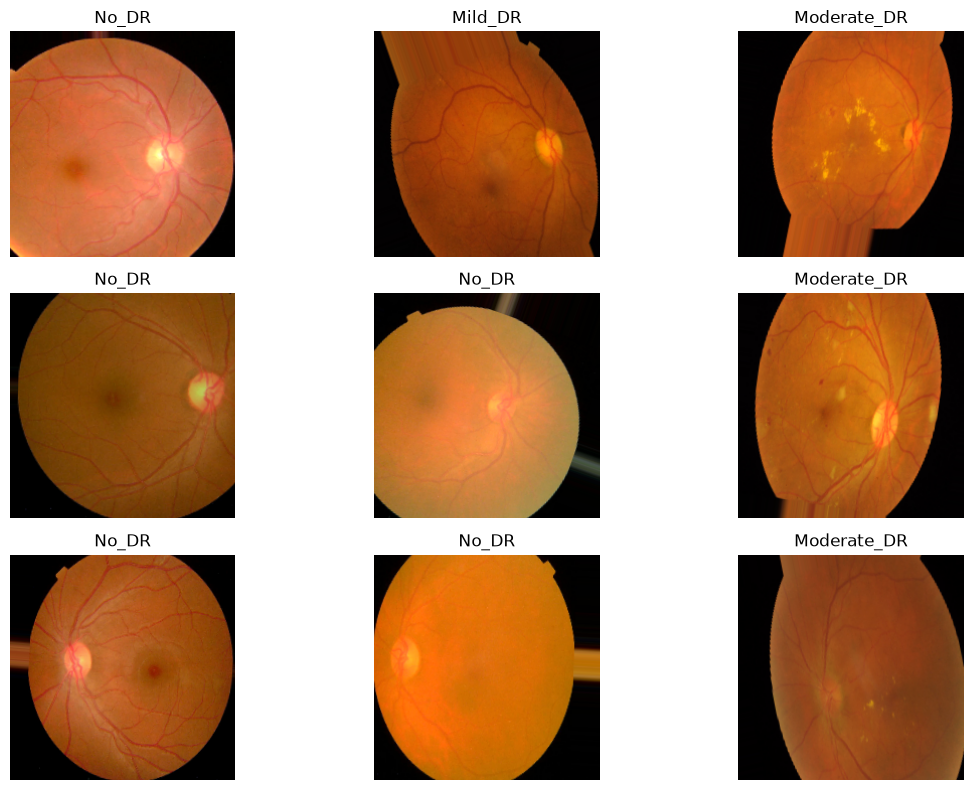

In [19]:
images, labels = next(train_generator)

plt.figure(figsize=(12, 8))

for index in range(9):
    plt.subplot(3, 3, index + 1)

    plt.imshow(images[index] / 255.0)

    class_index = np.argmax(labels[index])
    class_name = list(
        train_generator.class_indices.keys()
    )[class_index]

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

train_generator.reset()

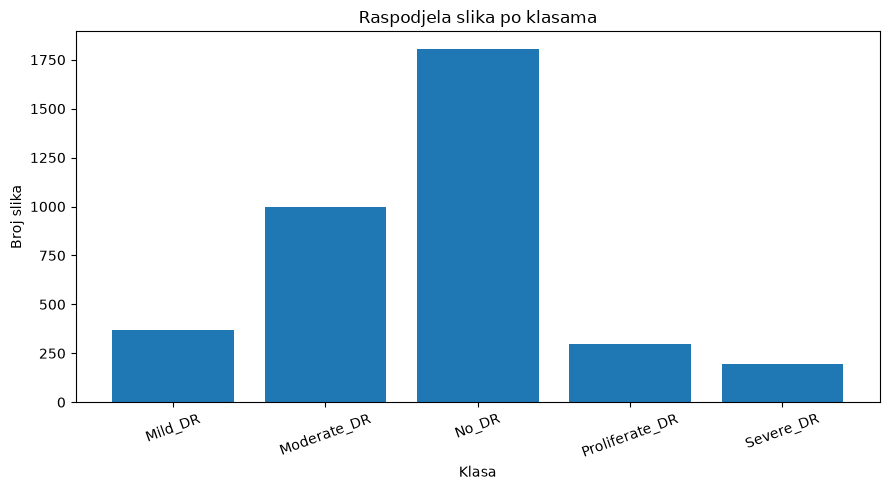

In [20]:
plt.figure(figsize=(9, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Raspodjela slika po klasama")
plt.xlabel("Klasa")
plt.ylabel("Broj slika")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [21]:
print("=" * 60)
print("Priprema podataka uspješno završena.")
print("=" * 60)

print(f"Broj trening slika: {train_generator.samples}")
print(
    f"Broj validacijskih slika: "
    f"{validation_generator.samples}"
)
print(f"Broj testnih slika: {test_generator.samples}")

print("\nBroj klasa:", train_generator.num_classes)
print("Oblik oznaka:", labels.shape)

print("\nKlase:")

for class_name, class_index in train_generator.class_indices.items():
    print(f"{class_index} -> {class_name}")

Priprema podataka uspješno završena.
Broj trening slika: 2562
Broj validacijskih slika: 546
Broj testnih slika: 554

Broj klasa: 5
Oblik oznaka: (32, 5)

Klase:
0 -> Mild_DR
1 -> Moderate_DR
2 -> No_DR
3 -> Proliferate_DR
4 -> Severe_DR


In [22]:
subset="training"
subset="validation"
rescale=1./255

In [23]:
images, labels = next(train_generator)

print("Minimum:", images.min())
print("Maksimum:", images.max())

Minimum: 0.0
Maksimum: 255.0
